In [1]:

import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not detected. Enable a GPU runtime before inference.")


Python: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
PyTorch: 2.14.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [2]:

%cd /content

!git clone https://github.com/mguti97/PnLCalib.git
%cd /content/PnLCalib

!ls


[Errno 2] No such file or directory: '/content'
/mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks
Cloning into 'PnLCalib'...
fatal: unable to access 'https://github.com/mguti97/PnLCalib.git/': Failed to connect to github.com port 443 after 142213 ms: Couldn't connect to server
[Errno 2] No such file or directory: '/content/PnLCalib'
/mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks
01_dataset_exploration.ipynb
02_sportsmot_to_yolo.ipynb
03_hard_mining_and_finetuning.ipynb
04_unseen_data_test_evaluation.ipynb
05_soccernet_ball_dataset_preparation.ipynb
05_soccernet_ball_detection_data_preparation_continuation.ipynb
06_ball_detection_final.ipynb
06_ball_detection_making2.ipynb
06_ball_detector_final2.ipynb
06_ball_detector_final3.ipynb
06_ball_detector_making1.ipynb
06_testing_ball_detector1.ipynb
07_player_tracking_bytetrack.ipynb
08_track_stitching.ipynb
09_identity_stitching.ipynb
10_AthletiQ_Performance_Analysis.ipynb
11_framewise_calibration_model.ipynb
__init__.py
byt

In [3]:

import json
from pathlib import Path

notebook_path = Path("11_framewise_calibration_model.ipynb")

if not notebook_path.exists():
    raise FileNotFoundError(
        f"Notebook not found in the current directory: {notebook_path.resolve()}"
    )

with notebook_path.open("r", encoding="utf-8") as f:
    notebook = json.load(f)

print("Notebook:", notebook_path.resolve())
print("Total cells:", len(notebook.get("cells", [])))

shown = 0

for index, cell in enumerate(notebook.get("cells", [])):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    outputs = cell.get("outputs", [])

    print(f"\n{'=' * 70}")
    print(f"CELL {index}")
    print("=" * 70)
    print(source[:5000] if source else "[Empty code cell]")

    for output in outputs:
        text = "".join(output.get("text", []))
        if text:
            print("\nOUTPUT:")
            print(text[:1500])

        data = output.get("data", {})
        if "text/plain" in data:
            plain = data["text/plain"]
            print("\nRESULT:")
            print(
                "".join(plain)[:1500]
                if isinstance(plain, list)
                else str(plain)[:1500]
            )

    shown += 1
    if shown >= 20:
        break

if shown == 0:
    print("No code cells found.")


Notebook: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/11_framewise_calibration_model.ipynb
Total cells: 3

CELL 0

import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not detected. Enable a GPU runtime before inference.")


OUTPUT:
Python: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
PyTorch: 2.14.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


CELL 1

%cd /content

!git clone https://github.com/mguti97/PnLCalib.git
%cd /content/PnLCalib

!ls


OUTPUT:
[Errno 2] No such file or directory: '/content'
/mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks
Cloning into 'PnLCalib'...
fatal: unable to access 'https://github.com/mguti97/PnLCalib.git/': Failed to connect to github.com port 443 after 142213 ms: Couldn't connect to server
[Errno 2] N

In [4]:

import subprocess
import shutil
from pathlib import Path

PROJECT_ROOT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")
NOTEBOOK_DIR = PROJECT_ROOT / "ai-engine" / "notebooks"
REPO_DIR = PROJECT_ROOT / "ai-engine" / "external" / "PnLCalib"

print("Project exists:", PROJECT_ROOT.exists())
print("Git executable:", shutil.which("git"))

result = subprocess.run(
    ["git", "ls-remote", "https://github.com/mguti97/PnLCalib.git", "HEAD"],
    capture_output=True,
    text=True,
    timeout=30,
)

print("Exit code:", result.returncode)
print("Output:", result.stdout[:1000])
print("Error:", result.stderr[:2000])


Project exists: True
Git executable: /usr/bin/git


TimeoutExpired: Command '['git', 'ls-remote', 'https://github.com/mguti97/PnLCalib.git', 'HEAD']' timed out after 30 seconds

In [5]:

import subprocess
import shutil
import socket
import requests

print("Git:", shutil.which("git"))

# Test DNS resolution.
try:
    print("GitHub IP:", socket.gethostbyname("github.com"))
except Exception as exc:
    print("DNS FAILED:", repr(exc))

# Test HTTPS independently of Git.
try:
    response = requests.get(
        "https://github.com",
        timeout=(5, 10),
    )
    print("GitHub HTTPS status:", response.status_code)
except Exception as exc:
    print("HTTPS FAILED:", repr(exc))

# Test access to the exact repository.
try:
    response = requests.get(
        "https://github.com/mguti97/PnLCalib",
        timeout=(5, 10),
    )
    print("Repository page status:", response.status_code)
    print("Final URL:", response.url)
except Exception as exc:
    print("REPOSITORY REQUEST FAILED:", repr(exc))


Git: /usr/bin/git
GitHub IP: 20.207.73.82
HTTPS FAILED: ConnectTimeout(MaxRetryError("HTTPSConnectionPool(host='github.com', port=443): Max retries exceeded with url: / (Caused by ConnectTimeoutError(<HTTPSConnection(host='github.com', port=443) at 0x70ca579c4bf0>, 'Connection to github.com timed out. (connect timeout=5)'))"))
REPOSITORY REQUEST FAILED: ConnectTimeout(MaxRetryError("HTTPSConnectionPool(host='github.com', port=443): Max retries exceeded with url: /mguti97/PnLCalib (Caused by ConnectTimeoutError(<HTTPSConnection(host='github.com', port=443) at 0x70cbbd58f470>, 'Connection to github.com timed out. (connect timeout=5)'))"))


In [6]:

import requests

urls = [
    "https://pypi.org/simple/",
    "https://raw.githubusercontent.com/",
    "https://github.com/",
]

for url in urls:
    try:
        response = requests.get(url, timeout=(5, 8))
        print(f"OK   {url} -> HTTP {response.status_code}")
    except Exception as exc:
        print(f"FAIL {url} -> {type(exc).__name__}: {exc}")


FAIL https://pypi.org/simple/ -> ConnectionError: HTTPSConnectionPool(host='pypi.org', port=443): Max retries exceeded with url: /simple/ (Caused by NewConnectionError("HTTPSConnection(host='pypi.org', port=443): Failed to establish a new connection: [Errno 101] Network is unreachable"))
FAIL https://raw.githubusercontent.com/ -> ConnectionError: HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: / (Caused by NewConnectionError("HTTPSConnection(host='raw.githubusercontent.com', port=443): Failed to establish a new connection: [Errno 101] Network is unreachable"))
FAIL https://github.com/ -> ConnectTimeout: HTTPSConnectionPool(host='github.com', port=443): Max retries exceeded with url: / (Caused by ConnectTimeoutError(<HTTPSConnection(host='github.com', port=443) at 0x70cbbd5bc3e0>, 'Connection to github.com timed out. (connect timeout=5)'))


In [8]:

from pathlib import Path

PROJECT_ROOT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")
REPO_DIR = PROJECT_ROOT / "ai-engine" / "notebooks" / "PnLCalib"

print("Repository exists:", REPO_DIR.exists())

if REPO_DIR.exists():
    print("\nRepository contents:")
    for item in sorted(REPO_DIR.iterdir()):
        print(" -", item.name)

    print("\nKey files:")
    for name in ["requirements.txt", "inference.py", "README.md"]:
        path = REPO_DIR / name
        print(f"{name}: {path.exists()}")
else:
    print("Copy the extracted repository into the destination above.")


Repository exists: True

Repository contents:
 - LICENSE
 - PnLCalib.yml
 - README.md
 - config
 - eval_wp.py
 - examples
 - figures
 - inference
 - inference.py
 - model
 - requirements.txt
 - scripts
 - sn_calibration
 - train.py
 - train_l.py
 - utils

Key files:
requirements.txt: True
inference.py: True
README.md: True


In [10]:

from pathlib import Path

REPO_DIR = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "ai-engine/notebooks/PnLCalib"
)

print("Repository root:", REPO_DIR)
print("Exists:", REPO_DIR.exists())

for filename in [
    "README.md",
    "requirements.txt",
    "inference.py",
    "PnLCalib.yml",
]:
    path = REPO_DIR / filename
    print(f"{filename}: {path.exists()}")

if not (REPO_DIR / "README.md").exists():
    raise FileNotFoundError("README.md is missing from the repository root.")

print("\n--- README: first 200 lines ---")
lines = (REPO_DIR / "README.md").read_text(
    encoding="utf-8", errors="replace"
).splitlines()

for number, line in enumerate(lines[:200], start=1):
    print(f"{number:03d}: {line}")

print("\n--- requirements.txt ---")
requirements = REPO_DIR / "requirements.txt"

if requirements.exists():
    print(requirements.read_text(encoding="utf-8", errors="replace"))

print("\n--- Checkpoint files ---")
for path in REPO_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in {
        ".pt", ".pth", ".ckpt", ".onnx", ".pkl"
    }:
        print(path.relative_to(REPO_DIR))


Repository root: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/PnLCalib
Exists: True
README.md: True
requirements.txt: True
inference.py: True
PnLCalib.yml: True

--- README: first 200 lines ---
001: # PnLCalib: Sports Field Registration via Points and Lines Optimization
002: Extension of the previous paper "No Bells, Just Whistles: Sports Field Registration by Leveraging Geometric Properties"
003: 
004: <div align="center">
005: 
006: [![Conference](https://img.shields.io/badge/PDF-CVIU-FBBC04?style=for-the-badge&logo=google-slides&logoColor=black)](https://www.sciencedirect.com/science/article/pii/S1077314226000792)
007: [![arXiv](https://img.shields.io/badge/arXiv-2404.08401-b31b1b.svg?style=for-the-badge)](https://arxiv.org/abs/2404.08401v2)
008: [![Conference](https://img.shields.io/badge/Preprint-SSRN-6b8bc7.svg?style=for-the-badge)](https://papers.ssrn.com/sol3/papers.cfm?abstract_id=4998149)
009:     
010: <p align="center"><img src=figures/FieldReconstruction-1.png 

In [11]:

from pathlib import Path
import importlib.metadata
import torch

REPO_DIR = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "ai-engine/notebooks/PnLCalib"
)

print("Repository:", REPO_DIR)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

print("\n--- Required pretrained weights ---")
for name in [
    "SV_kp",
    "SV_lines",
    "SV_FT_WC14_kp",
    "SV_FT_WC14_lines",
    "SV_FT_TSWC_kp",
    "SV_FT_TSWC_lines",
]:
    matches = [
        path for path in REPO_DIR.rglob("*")
        if path.is_file() and path.name == name
    ]
    print(f"{name}: {[str(p) for p in matches] or 'NOT FOUND'}")

print("\n--- Key project directories ---")
for name in ["model", "inference", "config", "utils"]:
    path = REPO_DIR / name
    print(f"{name}: exists={path.exists()}")

print("\n--- Installed dependencies ---")
for package in [
    "torch",
    "torchvision",
    "numpy",
    "opencv-python",
    "scipy",
    "shapely",
    "matplotlib",
    "PyYAML",
    "tqdm",
    "lsq-ellipse",
]:
    try:
        print(f"{package}: {importlib.metadata.version(package)}")
    except importlib.metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")


Repository: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/PnLCalib
PyTorch: 2.14.0+cu130
CUDA available: True

--- Required pretrained weights ---
SV_kp: NOT FOUND
SV_lines: NOT FOUND
SV_FT_WC14_kp: NOT FOUND
SV_FT_WC14_lines: NOT FOUND
SV_FT_TSWC_kp: NOT FOUND
SV_FT_TSWC_lines: NOT FOUND

--- Key project directories ---
model: exists=True
inference: exists=True
config: exists=True
utils: exists=True

--- Installed dependencies ---
torch: 2.14.0
torchvision: 0.29.0
numpy: 2.3.5
opencv-python: 5.0.0.93
scipy: 1.16.3
shapely: 2.1.2
matplotlib: 3.11.1
PyYAML: 6.0.3
tqdm: 4.69.1
lsq-ellipse: NOT INSTALLED


In [12]:
from pathlib import Path
import torch

REPO_DIR = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "ai-engine/notebooks/PnLCalib"
)

weights = {
    "keypoint_model": REPO_DIR / "SV_kp",
    "line_model": REPO_DIR / "SV_lines",
}

print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

all_found = True

for name, path in weights.items():
    exists = path.is_file()
    size_mb = path.stat().st_size / (1024 * 1024) if exists else 0
    valid_size = exists and size_mb > 0

    print(f"\n{name}")
    print("Path:", path)
    print("Exists:", exists)
    print(f"Size: {size_mb:.2f} MB" if exists else "Size: unavailable")

    if not valid_size:
        all_found = False

print("\nResult:", "READY FOR NEXT CHECK" if all_found else "WEIGHTS STILL MISSING")

CUDA available: True
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU

keypoint_model
Path: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/PnLCalib/SV_kp
Exists: True
Size: 252.69 MB

line_model
Path: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/PnLCalib/SV_lines
Exists: True
Size: 252.59 MB

Result: READY FOR NEXT CHECK


In [13]:
from pathlib import Path
import ast
import re

REPO_DIR = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "ai-engine/notebooks/PnLCalib"
)

FILES_TO_INSPECT = [
    REPO_DIR / "inference.py",
    REPO_DIR / "inference" / "__init__.py",
    REPO_DIR / "README.md",
    REPO_DIR / "requirements.txt",
]

print("=" * 75)
print("1. INFERENCE FILES AND IMPORTS")
print("=" * 75)

for file_path in FILES_TO_INSPECT[:2]:
    if not file_path.exists():
        print(f"\nNot present: {file_path}")
        continue

    print(f"\n--- {file_path.relative_to(REPO_DIR)} ---")
    source = file_path.read_text(encoding="utf-8", errors="replace")

    try:
        tree = ast.parse(source)
        for node in ast.walk(tree):
            if isinstance(node, (ast.Import, ast.ImportFrom)):
                print(ast.get_source_segment(source, node))
    except SyntaxError as exc:
        print("Could not parse imports:", exc)

    # Show where weights and model checkpoints are handled.
    for line_number, line in enumerate(source.splitlines(), start=1):
        if re.search(
            r"weight|checkpoint|load_state_dict|torch\.load|"
            r"argparse|pnl_refine|sys\.path",
            line,
            re.IGNORECASE,
        ):
            print(f"{line_number:4}: {line[:200]}")

print("\n" + "=" * 75)
print("2. REQUIREMENTS")
print("=" * 75)

requirements_file = REPO_DIR / "requirements.txt"
if requirements_file.exists():
    for line in requirements_file.read_text(
        encoding="utf-8", errors="replace"
    ).splitlines():
        if line.strip() and not line.lstrip().startswith("#"):
            print(line)

print("\n" + "=" * 75)
print("3. AVAILABLE ATHLETIQ CALIBRATION FRAMES")
print("=" * 75)

PROJECT_DIR = REPO_DIR.parents[2]
FRAME_DIR = PROJECT_DIR / "outputs" / "calibration" / "frames"

print("Expected frame directory:", FRAME_DIR)
print("Directory exists:", FRAME_DIR.is_dir())

if FRAME_DIR.is_dir():
    frames = sorted(
        p for p in FRAME_DIR.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    )
    print("Number of frames:", len(frames))
    for frame in frames[:8]:
        print(f"  {frame.name} ({frame.stat().st_size / 1024:.1f} KB)")
else:
    print("Please verify the calibration-frame directory.")

1. INFERENCE FILES AND IMPORTS

--- inference.py ---
import cv2
import yaml
import torch
import argparse
import numpy as np
import matplotlib.pyplot as plt
import torchvision.transforms as T
import torchvision.transforms.functional as f
from tqdm import tqdm
from PIL import Image
from matplotlib.patches import Polygon
from model.cls_hrnet import get_cls_net
from model.cls_hrnet_l import get_cls_net as get_cls_net_l
from utils.utils_calib import FramebyFrameCalib, pan_tilt_roll_to_orientation
from utils.utils_heatmap import get_keypoints_from_heatmap_batch_maxpool, get_keypoints_from_heatmap_batch_maxpool_l, \
    complete_keypoints, coords_to_dict
   4: import argparse
  65: def inference(cam, frame, model, model_l, kp_threshold, line_threshold, pnl_refine):
  86:     final_params_dict = cam.heuristic_voting(refine_lines=pnl_refine)
 138: def process_input(input_path, input_type, model_kp, model_line, kp_threshold, line_threshold, pnl_refine,
 161:             final_params_dict = infer

In [14]:
from pathlib import Path
import ast
import sys
import traceback

REPO_DIR = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "ai-engine/notebooks/PnLCalib"
)

# Make the repository's modules importable in this notebook.
repo_path = str(REPO_DIR)
if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

print("=" * 70)
print("1. CHECK REQUIRED IMPORTS")
print("=" * 70)

modules_to_check = [
    ("cv2", "opencv-python"),
    ("yaml", "PyYAML"),
    ("torch", "torch"),
    ("torchvision", "torchvision"),
    ("numpy", "numpy"),
    ("matplotlib", "matplotlib"),
    ("tqdm", "tqdm"),
    ("PIL", "Pillow"),
    ("scipy", "scipy"),
    ("shapely", "shapely"),
    ("lsqellipse", "lsq-ellipse"),
]

import importlib

for module_name, package_name in modules_to_check:
    try:
        importlib.import_module(module_name)
        print(f"[OK]      {module_name} ({package_name})")
    except Exception as exc:
        print(f"[FAILED]  {module_name} ({package_name})")
        print(f"          {type(exc).__name__}: {exc}")

print("\n" + "=" * 70)
print("2. TEST PNLCalib MODULE IMPORT")
print("=" * 70)

try:
    import inference as pnl_inference
    print("[OK] inference.py imported successfully")
except Exception:
    print("[FAILED] inference.py import failed")
    traceback.print_exc()

print("\n" + "=" * 70)
print("3. INFERENCE ARGUMENTS AND MODEL LOADING")
print("=" * 70)

inference_file = REPO_DIR / "inference.py"
source_lines = inference_file.read_text(
    encoding="utf-8", errors="replace"
).splitlines()

for start, end in [(195, 255)]:
    for line_number in range(start, min(end, len(source_lines)) + 1):
        print(f"{line_number:4}: {source_lines[line_number - 1]}")

print("\n" + "=" * 70)
print("4. CONFIG FILES")
print("=" * 70)

config_dir = REPO_DIR / "config"

for path in sorted(config_dir.rglob("*")):
    if path.is_file() and path.suffix.lower() in {".yaml", ".yml", ".json"}:
        print(f"\n--- {path.relative_to(REPO_DIR)} ---")
        try:
            lines = path.read_text(
                encoding="utf-8", errors="replace"
            ).splitlines()
            for line in lines[:100]:
                print(line)
            if len(lines) > 100:
                print(f"... {len(lines) - 100} more lines")
        except Exception as exc:
            print("Could not read file:", exc)

print("\n" + "=" * 70)
print("5. WEIGHT FILES")
print("=" * 70)

for name in ["SV_kp", "SV_lines"]:
    path = REPO_DIR / name
    print(
        f"{name}: exists={path.is_file()}, "
        f"bytes={path.stat().st_size if path.is_file() else 0}"
    )

1. CHECK REQUIRED IMPORTS
[OK]      cv2 (opencv-python)
[OK]      yaml (PyYAML)
[OK]      torch (torch)
[OK]      torchvision (torchvision)
[OK]      numpy (numpy)
[OK]      matplotlib (matplotlib)
[OK]      tqdm (tqdm)
[OK]      PIL (Pillow)
[OK]      scipy (scipy)
[OK]      shapely (shapely)
[FAILED]  lsqellipse (lsq-ellipse)
          ModuleNotFoundError: No module named 'lsqellipse'

2. TEST PNLCalib MODULE IMPORT
[OK] inference.py imported successfully

3. INFERENCE ARGUMENTS AND MODEL LOADING
 195: 
 196:         if save_path != "":
 197:             cv2.imwrite(save_path, projected_frame)
 198:         else:
 199:             plt.imshow(cv2.cvtColor(projected_frame, cv2.COLOR_BGR2RGB))
 200:             plt.axis('off')
 201:             plt.show()
 202: 
 203: if __name__ == "__main__":
 204: 
 205:     parser = argparse.ArgumentParser(description="Process video or image and plot lines on each frame.")
 206:     parser.add_argument("--weights_kp", type=str, help="Path to the mod

In [17]:
import socket
import importlib.util
import subprocess
import sys

print("Python:", sys.executable)
print("lsqellipse already importable:", importlib.util.find_spec("lsqellipse") is not None)

try:
    print("PyPI DNS:", socket.gethostbyname("pypi.org"))
except Exception as exc:
    print("PyPI DNS failed:", repr(exc))

try:
    result = subprocess.run(
        [
            sys.executable, "-m", "pip", "index", "versions",
            "lsq-ellipse", "--timeout", "5", "--retries", "0"
        ],
        capture_output=True,
        text=True,
        timeout=12,
    )
    print("pip exit code:", result.returncode)
    print((result.stdout + result.stderr)[-2500:])
except subprocess.TimeoutExpired:
    print("PyPI check timed out; network access may be blocked.")

Python: /home/jatin/tf312/bin/python
lsqellipse already importable: False
PyPI DNS: 151.101.128.223
PyPI check timed out; network access may be blocked.


In [18]:
from pathlib import Path

folder = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "ai-engine/notebooks/PnLCalib/lsq-ellipse-2.2.1"
)

if not folder.is_dir():
    print("Folder not found:", folder)
else:
    print("Folder contents:")
    for path in sorted(folder.iterdir()):
        print(("DIR  " if path.is_dir() else "FILE "), path.name)

    print("\nSetup files:")
    for name in [
        "pyproject.toml",
        "setup.py",
        "setup.cfg",
        "PKG-INFO",
        "README.md",
    ]:
        path = folder / name
        print(f"{name}: {'FOUND' if path.exists() else 'missing'}")

Folder contents:
FILE  LICENSE
FILE  PKG-INFO
FILE  README.md
FILE  ellipse.py
DIR   lsq_ellipse.egg-info
FILE  setup.cfg
FILE  setup.py

Setup files:
pyproject.toml: missing
setup.py: FOUND
setup.cfg: FOUND
PKG-INFO: FOUND
README.md: FOUND


In [22]:
from pathlib import Path
import subprocess
import sys

PACKAGE_DIR = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "ai-engine/notebooks/PnLCalib/lsq-ellipse-2.2.1"
)

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--no-index",
        "--no-deps",
        "--no-build-isolation",
        str(PACKAGE_DIR),
    ],
    capture_output=True,
    text=True,
    timeout=60,
)

print("STDOUT:\n", result.stdout)
print("STDERR:\n", result.stderr)

if result.returncode != 0:
    print("Installation failed. Share the error above.")
else:
    print("Installation succeeded.")

STDOUT:
 Processing ./PnLCalib/lsq-ellipse-2.2.1
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for lsq-ellipse: filename=lsq_ellipse-2.2.1-py3-none-any.whl size=5704 sha256=32b76b8d08f8e2303fbde05bad03b24ac2f270e4d8b1d0908bb1c2a5f63fc6e5
  Stored in directory: /home/jatin/.cache/pip/wheels/44/cc/7a/9811d2b3ff585c516b602928bcfecf337976286f79a8b2c271
Successfully built lsq-ellipse

STDERR:
 
Installation succeeded.


In [23]:
from ellipse import LsqEllipse

print("SUCCESS: LsqEllipse is available.")

SUCCESS: LsqEllipse is available.


In [24]:
from pathlib import Path
import os
import yaml
import torch

REPO_DIR = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "ai-engine/notebooks/PnLCalib"
)

os.chdir(REPO_DIR)

from model.cls_hrnet import get_cls_net
from model.cls_hrnet_l import get_cls_net as get_cls_net_l

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

with open(REPO_DIR / "config/hrnetv2_w48.yaml", "r") as f:
    cfg_kp = yaml.safe_load(f)

with open(REPO_DIR / "config/hrnetv2_w48_l.yaml", "r") as f:
    cfg_lines = yaml.safe_load(f)

print("\nBuilding keypoint model...")
model_kp = get_cls_net(cfg_kp)

state_kp = torch.load(
    REPO_DIR / "SV_kp",
    map_location="cpu",
    weights_only=True,
)
model_kp.load_state_dict(state_kp, strict=True)
model_kp.to(device).eval()
del state_kp

print("Keypoint model loaded successfully.")

print("\nBuilding line model...")
model_lines = get_cls_net_l(cfg_lines)

state_lines = torch.load(
    REPO_DIR / "SV_lines",
    map_location="cpu",
    weights_only=True,
)
model_lines.load_state_dict(state_lines, strict=True)
model_lines.to(device).eval()
del state_lines

print("Line model loaded successfully.")

if device.type == "cuda":
    print(
        f"\nGPU memory allocated: "
        f"{torch.cuda.memory_allocated() / 1024**3:.2f} GiB"
    )
    print(
        f"GPU memory reserved: "
        f"{torch.cuda.memory_reserved() / 1024**3:.2f} GiB"
    )

print("\nSUCCESS: both pretrained models are ready.")

Device: cuda:0
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU

Building keypoint model...
Keypoint model loaded successfully.

Building line model...
Line model loaded successfully.

GPU memory allocated: 0.49 GiB
GPU memory reserved: 0.54 GiB

SUCCESS: both pretrained models are ready.


In [25]:
import inspect
import inference as pnl_inference

print("=" * 70)
print("INFERENCE FUNCTION")
print("=" * 70)
print(inspect.getsource(pnl_inference.inference))

print("\n" + "=" * 70)
print("INPUT PROCESSING FUNCTION")
print("=" * 70)
print(inspect.getsource(pnl_inference.process_input))

INFERENCE FUNCTION
def inference(cam, frame, model, model_l, kp_threshold, line_threshold, pnl_refine):
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frame = Image.fromarray(frame)

    frame = f.to_tensor(frame).float().unsqueeze(0)
    _, _, h_original, w_original = frame.size()
    frame = frame if frame.size()[-1] == 960 else transform2(frame)
    frame = frame.to(device)
    b, c, h, w = frame.size()

    with torch.no_grad():
        heatmaps = model(frame)
        heatmaps_l = model_l(frame)

    kp_coords = get_keypoints_from_heatmap_batch_maxpool(heatmaps[:,:-1,:,:])
    line_coords = get_keypoints_from_heatmap_batch_maxpool_l(heatmaps_l[:,:-1,:,:])
    kp_dict = coords_to_dict(kp_coords, threshold=kp_threshold)
    lines_dict = coords_to_dict(line_coords, threshold=line_threshold)
    kp_dict, lines_dict = complete_keypoints(kp_dict[0], lines_dict[0], w=w, h=h, normalize=True)

    cam.update(kp_dict, lines_dict)
    final_params_dict = cam.heuristic_voting(refine_li

Frame: /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/calibration/frames/frame_000000_0000.00s.jpg
Device: cuda:0
Frame dimensions: 768 x 432

Running keypoint and line detection...

Inference completed.
Calibration returned: True

Camera parameters:
{
  "mode": "full",
  "use_ransac": 0,
  "rep_err": 1.67398852219666,
  "cam_params": {
    "pan_degrees": 0.23457673496281842,
    "tilt_degrees": 81.01607918345472,
    "roll_degrees": -0.5587537938514675,
    "x_focal_length": 1203.0055864622313,
    "y_focal_length": 1203.0055864622313,
    "principal_point": [
      383.5,
      215.5
    ],
    "position_meters": [
      -0.48819698567498704,
      57.3131435542348,
      -11.992547351511938
    ],
    "rotation_matrix": [
      [
        0.9999503028296305,
        0.0025711067818587584,
        -0.009632304025861432
      ],
      [
        0.009112560094543849,
        0.15618847076033845,
        0.9876852347028735
      ],
      [
        0.004043899040984265,
        -0.987723924

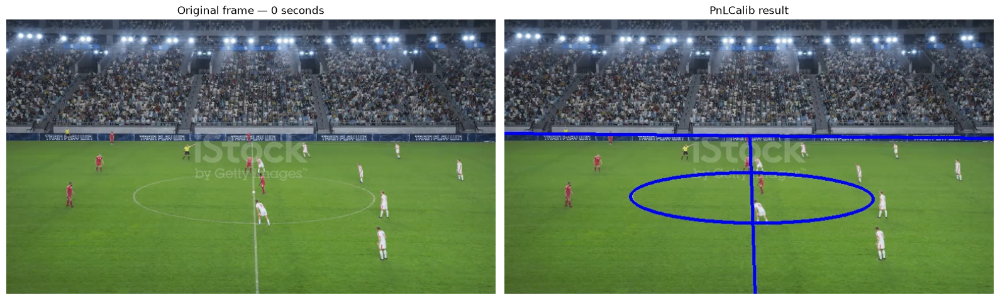

In [26]:
from pathlib import Path
import json
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
import torchvision.transforms as T

import inference as pnl_inference
from utils.utils_calib import FramebyFrameCalib

# --------------------------------------------------
# 1. Paths and runtime configuration
# --------------------------------------------------
PROJECT_DIR = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")
REPO_DIR = PROJECT_DIR / "ai-engine" / "notebooks" / "PnLCalib"
FRAME_DIR = PROJECT_DIR / "outputs" / "calibration" / "frames"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "calibration" / "pnlcalib_test"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FRAME_PATH = FRAME_DIR / "frame_000000_0000.00s.jpg"
OVERLAY_PATH = OUTPUT_DIR / "frame_000000_pnlcalib.jpg"
PARAMS_PATH = OUTPUT_DIR / "frame_000000_camera_params.json"

if not FRAME_PATH.is_file():
    raise FileNotFoundError(f"Calibration frame not found: {FRAME_PATH}")

# inference() refers to these variables in its module's global scope.
pnl_inference.device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)
pnl_inference.transform2 = T.Resize((540, 960))

print("Frame:", FRAME_PATH)
print("Device:", pnl_inference.device)

# --------------------------------------------------
# 2. Read the frame and initialize calibration
# --------------------------------------------------
frame = cv2.imread(str(FRAME_PATH))

if frame is None:
    raise RuntimeError(f"OpenCV could not read {FRAME_PATH}")

height, width = frame.shape[:2]
print(f"Frame dimensions: {width} x {height}")

cam = FramebyFrameCalib(
    iwidth=width,
    iheight=height,
    denormalize=True,
)

# --------------------------------------------------
# 3. Run PnLCalib inference
# --------------------------------------------------
print("\nRunning keypoint and line detection...")

with torch.inference_mode():
    params = pnl_inference.inference(
        cam=cam,
        frame=frame.copy(),
        model=model_kp,
        model_l=model_lines,
        kp_threshold=0.3434,
        line_threshold=0.7867,
        pnl_refine=True,
    )

print("\nInference completed.")
print("Calibration returned:", params is not None)

# --------------------------------------------------
# 4. Save parameters and generate pitch overlay
# --------------------------------------------------
def to_json_safe(value):
    if isinstance(value, dict):
        return {str(k): to_json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_json_safe(v) for v in value]
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, torch.Tensor):
        return value.detach().cpu().tolist()
    if isinstance(value, (str, int, float, bool)) or value is None:
        return value
    return repr(value)

if params is None:
    print(
        "\nNo camera parameters were returned. "
        "Saving the original frame for diagnosis."
    )
    cv2.imwrite(str(OVERLAY_PATH), frame)

else:
    print("\nCamera parameters:")
    print(json.dumps(to_json_safe(params), indent=2))

    with open(PARAMS_PATH, "w", encoding="utf-8") as f:
        json.dump(to_json_safe(params), f, indent=2)

    if not hasattr(pnl_inference, "projection_from_cam_params"):
        raise AttributeError(
            "projection_from_cam_params is not available in inference.py. "
            "We need to inspect the repository's projection utilities."
        )

    if not hasattr(pnl_inference, "project"):
        raise AttributeError(
            "project is not available in inference.py. "
            "We need to inspect the repository's projection utilities."
        )

    projection = pnl_inference.projection_from_cam_params(params)
    projected_frame = pnl_inference.project(frame.copy(), projection)

    if projected_frame is None:
        raise RuntimeError("PnLCalib returned no projected frame.")

    if not cv2.imwrite(str(OVERLAY_PATH), projected_frame):
        raise RuntimeError(f"Could not save overlay to {OVERLAY_PATH}")

    print("\nSaved camera parameters:", PARAMS_PATH)
    print("Saved projected frame:", OVERLAY_PATH)

# --------------------------------------------------
# 5. Display original and result side by side
# --------------------------------------------------
result = cv2.imread(str(OVERLAY_PATH))

if result is None:
    raise RuntimeError("Could not read the saved output image.")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original frame — 0 seconds")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
axes[1].set_title(
    "PnLCalib result" if params is not None else "Original — calibration unavailable"
)
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [27]:

from pathlib import Path
import os
import json
import csv
import cv2
import numpy as np
import torch
import torchvision.transforms as T

import inference as pnl_inference
from utils.utils_calib import FramebyFrameCalib

PROJECT_DIR = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")
REPO_DIR = PROJECT_DIR / "ai-engine" / "notebooks" / "PnLCalib"
FRAME_DIR = PROJECT_DIR / "outputs" / "calibration" / "frames"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "calibration" / "pnlcalib_batch"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

os.chdir(REPO_DIR)
pnl_inference.device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)
pnl_inference.transform2 = T.Resize((540, 960))

frames = sorted(
    p for p in FRAME_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

if not frames:
    raise FileNotFoundError(f"No frames found in {FRAME_DIR}")

rows = []

for index, frame_path in enumerate(frames, start=1):
    frame = cv2.imread(str(frame_path))
    if frame is None:
        print(f"[SKIP] Could not read {frame_path.name}")
        continue

    height, width = frame.shape[:2]
    cam = FramebyFrameCalib(
        iwidth=width,
        iheight=height,
        denormalize=True,
    )

    print(f"[{index}/{len(frames)}] {frame_path.name}")

    try:
        with torch.inference_mode():
            params = pnl_inference.inference(
                cam=cam,
                frame=frame.copy(),
                model=model_kp,
                model_l=model_lines,
                kp_threshold=0.3434,
                line_threshold=0.7867,
                pnl_refine=True,
            )

        row = {
            "frame": frame_path.name,
            "width": width,
            "height": height,
            "calibration_returned": params is not None,
            "mode": None,
            "rep_err": None,
            "pan_degrees": None,
            "tilt_degrees": None,
            "roll_degrees": None,
            "x_focal_length": None,
            "y_focal_length": None,
            "overlay_path": None,
            "error": None,
        }

        if params is not None:
            row["mode"] = params.get("mode")
            row["rep_err"] = params.get("rep_err")

            cp = params.get("cam_params") or {}
            for key in [
                "pan_degrees",
                "tilt_degrees",
                "roll_degrees",
                "x_focal_length",
                "y_focal_length",
            ]:
                row[key] = cp.get(key)

            safe_name = frame_path.stem
            params_path = OUTPUT_DIR / f"{safe_name}_params.json"
            overlay_path = OUTPUT_DIR / f"{safe_name}_overlay.jpg"

            with open(params_path, "w", encoding="utf-8") as f:
                json.dump(params, f, indent=2, default=str)

            projection = pnl_inference.projection_from_cam_params(params)
            projected = pnl_inference.project(frame.copy(), projection)

            if projected is not None and cv2.imwrite(
                str(overlay_path), projected
            ):
                row["overlay_path"] = str(overlay_path)

        rows.append(row)
        print(
            f"    returned={row['calibration_returned']}, "
            f"rep_err={row['rep_err']}, "
            f"mode={row['mode']}"
        )

    except Exception as exc:
        rows.append({
            "frame": frame_path.name,
            "width": width,
            "height": height,
            "calibration_returned": False,
            "mode": None,
            "rep_err": None,
            "pan_degrees": None,
            "tilt_degrees": None,
            "roll_degrees": None,
            "x_focal_length": None,
            "y_focal_length": None,
            "overlay_path": None,
            "error": f"{type(exc).__name__}: {exc}",
        })
        print(f"    ERROR: {type(exc).__name__}: {exc}")

csv_path = OUTPUT_DIR / "calibration_summary.csv"

fieldnames = list(rows[0].keys()) if rows else []
with open(csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(rows)

successful = sum(r["calibration_returned"] for r in rows)

print("\n=== BATCH SUMMARY ===")
print("Frames processed:", len(rows))
print("Calibrations returned:", successful)
print("Summary CSV:", csv_path)
print("Output directory:", OUTPUT_DIR)


[1/16] frame_000000_0000.00s.jpg
    returned=True, rep_err=1.67398852219666, mode=full
[2/16] frame_000050_0002.00s.jpg
    returned=True, rep_err=3.2195030807918394, mode=full
[3/16] frame_000100_0004.00s.jpg
    returned=True, rep_err=2.410515797807447, mode=full
[4/16] frame_000150_0006.00s.jpg
    returned=True, rep_err=2.87963833483717, mode=full
[5/16] frame_000200_0008.00s.jpg
    returned=True, rep_err=1.7399804049418246, mode=full
[6/16] frame_000250_0010.00s.jpg
    returned=True, rep_err=1.938666081201709, mode=full
[7/16] frame_000300_0012.00s.jpg
    returned=True, rep_err=1.860463348793653, mode=full
[8/16] frame_000350_0014.00s.jpg
    returned=True, rep_err=1.8001341256846943, mode=full
[9/16] frame_000400_0016.00s.jpg
    returned=True, rep_err=0.9685148745118419, mode=full
[10/16] frame_000450_0018.00s.jpg
    returned=True, rep_err=2.4151368897143857, mode=full
[11/16] frame_000500_0020.00s.jpg
    returned=True, rep_err=2.5802932148703013, mode=full
[12/16] frame_0

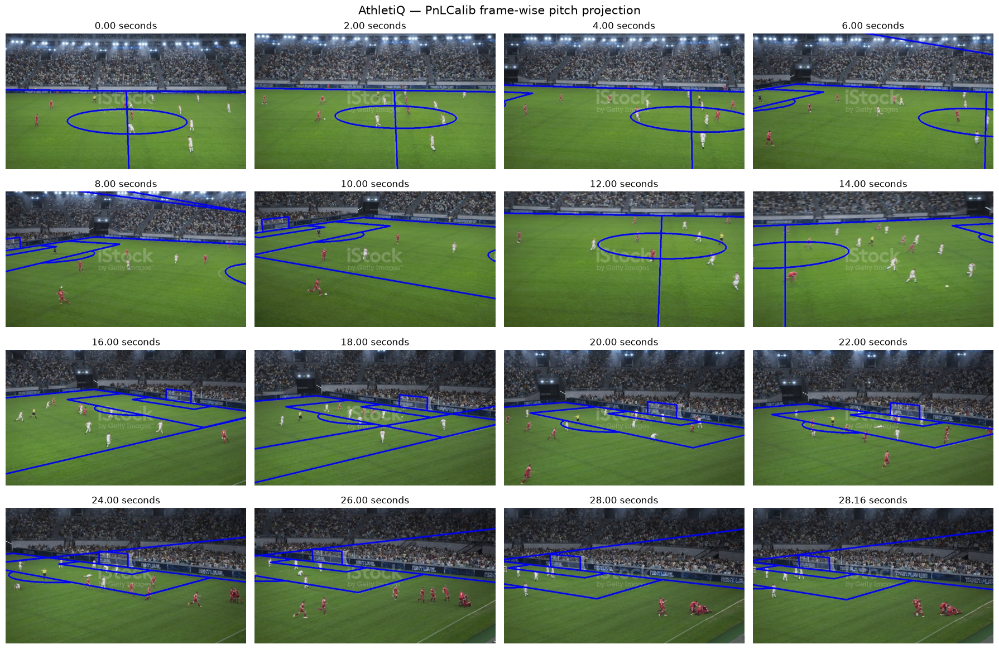

Displayed 16 overlays.
Overlay directory: /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/calibration/pnlcalib_batch


In [28]:

from pathlib import Path
import re
import cv2
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")
OVERLAY_DIR = (
    PROJECT_DIR / "outputs" / "calibration" / "pnlcalib_batch"
)
FRAME_DIR = PROJECT_DIR / "outputs" / "calibration" / "frames"

def timestamp_from_name(name):
    match = re.search(r"_(\d+(?:\.\d+)?)s", name)
    return float(match.group(1)) if match else -1.0

originals = {
    timestamp_from_name(p.name): p
    for p in FRAME_DIR.glob("*")
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
}

overlays = sorted(
    OVERLAY_DIR.glob("*_overlay.jpg"),
    key=lambda p: timestamp_from_name(p.name),
)

if not overlays:
    raise FileNotFoundError(
        f"No overlay images found in {OVERLAY_DIR}"
    )

fig, axes = plt.subplots(4, 4, figsize=(18, 12))
axes = axes.flatten()

for ax, overlay_path in zip(axes, overlays):
    image = cv2.imread(str(overlay_path))
    if image is None:
        ax.set_title(f"Unreadable: {overlay_path.name}")
        ax.axis("off")
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    timestamp = timestamp_from_name(overlay_path.name)

    ax.imshow(image)
    ax.set_title(f"{timestamp:.2f} seconds")
    ax.axis("off")

for ax in axes[len(overlays):]:
    ax.axis("off")

fig.suptitle(
    "AthletiQ — PnLCalib frame-wise pitch projection",
    fontsize=15,
)
plt.tight_layout()
plt.show()

print(f"Displayed {len(overlays)} overlays.")
print("Overlay directory:", OVERLAY_DIR)


In [29]:

from pathlib import Path
import inspect
import os
import traceback

REPO_DIR = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "ai-engine/notebooks/PnLCalib"
)
os.chdir(REPO_DIR)

import inference as pnl_inference
import utils.utils_calib as calib_utils

print("=" * 75)
print("1. PROJECTION FUNCTION IMPLEMENTATIONS")
print("=" * 75)

for module in [pnl_inference, calib_utils]:
    for name in [
        "projection_from_cam_params",
        "project",
        "FramebyFrameCalib",
        "pan_tilt_roll_to_orientation",
    ]:
        obj = getattr(module, name, None)
        if obj is not None:
            print(f"\n--- {module.__name__}.{name} ---")
            try:
                print(inspect.getsource(obj))
            except (OSError, TypeError):
                print("Source unavailable.")

print("\n" + "=" * 75)
print("2. CALIBRATION UPDATE AND REFINEMENT")
print("=" * 75)

for name in ["update", "heuristic_voting"]:
    obj = getattr(calib_utils.FramebyFrameCalib, name, None)
    if obj is not None:
        print(f"\n--- FramebyFrameCalib.{name} ---")
        try:
            print(inspect.getsource(obj))
        except (OSError, TypeError):
            print("Source unavailable.")

print("\n" + "=" * 75)
print("3. SAVED PARAMETER SUMMARY")
print("=" * 75)

import json
import numpy as np

PARAMS_DIR = (
    Path("/mnt/d/My Projects/AthletiQ/AthletiQ")
    / "outputs/calibration/pnlcalib_batch"
)

for path in sorted(PARAMS_DIR.glob("*_params.json")):
    try:
        data = json.loads(path.read_text(encoding="utf-8"))
        cp = data.get("cam_params") or {}
        print(
            path.name,
            "| mode:", data.get("mode"),
            "| rep_err:", data.get("rep_err"),
            "| pan:", cp.get("pan_degrees"),
            "| tilt:", cp.get("tilt_degrees"),
            "| roll:", cp.get("roll_degrees"),
        )
    except Exception as exc:
        print(path.name, "| ERROR:", exc)


1. PROJECTION FUNCTION IMPLEMENTATIONS

--- inference.projection_from_cam_params ---
def projection_from_cam_params(final_params_dict):
    cam_params = final_params_dict["cam_params"]
    x_focal_length = cam_params['x_focal_length']
    y_focal_length = cam_params['y_focal_length']
    principal_point = np.array(cam_params['principal_point'])
    position_meters = np.array(cam_params['position_meters'])
    rotation = np.array(cam_params['rotation_matrix'])

    It = np.eye(4)[:-1]
    It[:, -1] = -position_meters
    Q = np.array([[x_focal_length, 0, principal_point[0]],
                  [0, y_focal_length, principal_point[1]],
                  [0, 0, 1]])
    P = Q @ (rotation @ It)

    return P


--- inference.project ---
def project(frame, P):

    for line in lines_coords:
        w1 = line[0]
        w2 = line[1]
        i1 = P @ np.array([w1[0]-105/2, w1[1]-68/2, w1[2], 1])
        i2 = P @ np.array([w2[0]-105/2, w2[1]-68/2, w2[2], 1])
        i1 /= i1[-1]
        i2 /= i2[

{'frame': 'frame_000000_0000.00s.jpg', 'pnl_refine': False, 'returned': True, 'rep_err': np.float64(1.6739885221966684), 'mode': 'full', 'overlay': '/mnt/d/My Projects/AthletiQ/AthletiQ/outputs/calibration/refinement_ab_test/frame_000000_0000.00s_unrefined.jpg'}
{'frame': 'frame_000000_0000.00s.jpg', 'pnl_refine': True, 'returned': True, 'rep_err': np.float64(1.67398852219666), 'mode': 'full', 'overlay': '/mnt/d/My Projects/AthletiQ/AthletiQ/outputs/calibration/refinement_ab_test/frame_000000_0000.00s_refined.jpg'}
{'frame': 'frame_000200_0008.00s.jpg', 'pnl_refine': False, 'returned': True, 'rep_err': np.float64(1.707960206067842), 'mode': 'full', 'overlay': '/mnt/d/My Projects/AthletiQ/AthletiQ/outputs/calibration/refinement_ab_test/frame_000200_0008.00s_unrefined.jpg'}
{'frame': 'frame_000200_0008.00s.jpg', 'pnl_refine': True, 'returned': True, 'rep_err': np.float64(1.7399804049418246), 'mode': 'full', 'overlay': '/mnt/d/My Projects/AthletiQ/AthletiQ/outputs/calibration/refinement_a

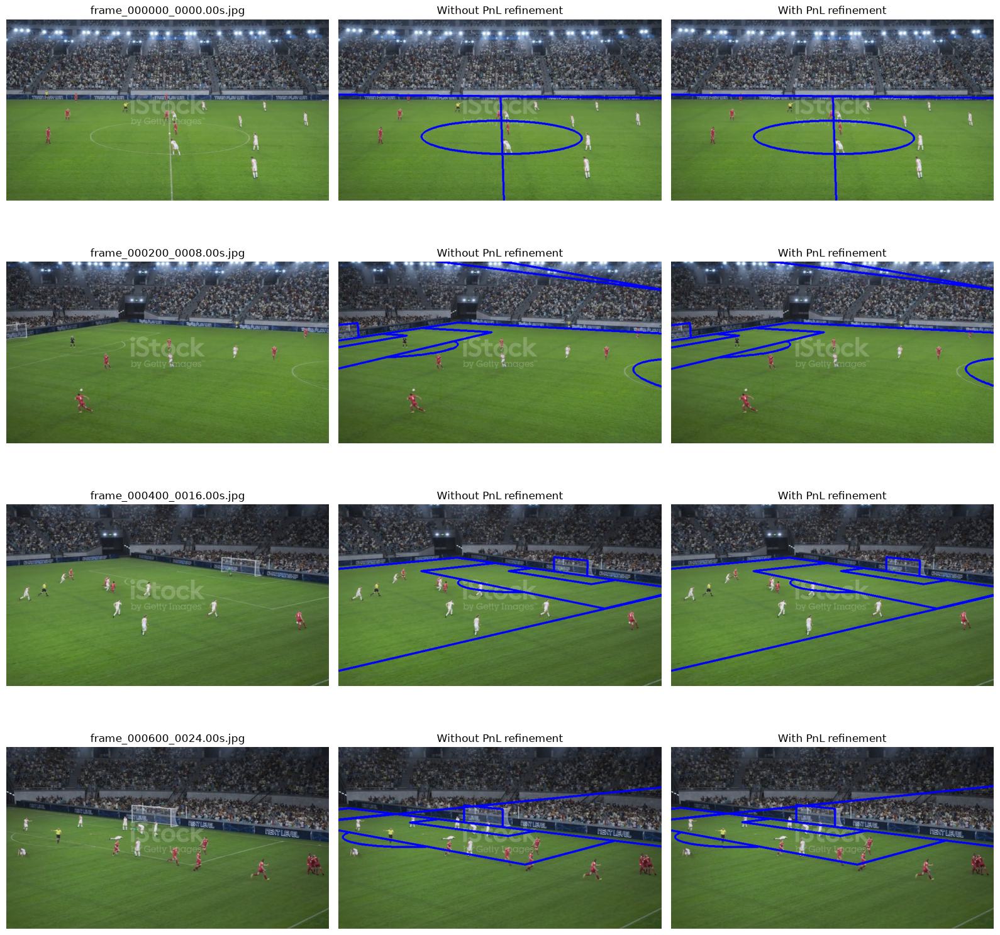


Saved comparison: /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/calibration/refinement_ab_test/comparison.csv
Saved overlays: /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/calibration/refinement_ab_test


In [30]:

from pathlib import Path
import os
import csv
import cv2
import torch
import matplotlib.pyplot as plt
import torchvision.transforms as T

PROJECT_DIR = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")
REPO_DIR = PROJECT_DIR / "ai-engine/notebooks/PnLCalib"
FRAME_DIR = PROJECT_DIR / "outputs/calibration/frames"
OUT_DIR = PROJECT_DIR / "outputs/calibration/refinement_ab_test"
OUT_DIR.mkdir(parents=True, exist_ok=True)

os.chdir(REPO_DIR)
pnl_inference.device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)
pnl_inference.transform2 = T.Resize((540, 960))

selected_frames = [
    FRAME_DIR / "frame_000000_0000.00s.jpg",
    FRAME_DIR / "frame_000200_0008.00s.jpg",
    FRAME_DIR / "frame_000400_0016.00s.jpg",
    FRAME_DIR / "frame_000600_0024.00s.jpg",
]

rows = []
display_items = []

for frame_path in selected_frames:
    frame = cv2.imread(str(frame_path))
    if frame is None:
        print("Skipping unreadable frame:", frame_path)
        continue

    height, width = frame.shape[:2]

    for refine in [False, True]:
        cam = FramebyFrameCalib(
            iwidth=width,
            iheight=height,
            denormalize=True,
        )

        with torch.inference_mode():
            params = pnl_inference.inference(
                cam=cam,
                frame=frame.copy(),
                model=model_kp,
                model_l=model_lines,
                kp_threshold=0.3434,
                line_threshold=0.7867,
                pnl_refine=refine,
            )

        row = {
            "frame": frame_path.name,
            "pnl_refine": refine,
            "returned": params is not None,
            "rep_err": params.get("rep_err") if params else None,
            "mode": params.get("mode") if params else None,
        }

        if params is not None:
            projection = pnl_inference.projection_from_cam_params(params)
            projected = pnl_inference.project(frame.copy(), projection)

            suffix = "refined" if refine else "unrefined"
            output_path = OUT_DIR / f"{frame_path.stem}_{suffix}.jpg"

            if projected is not None and cv2.imwrite(
                str(output_path), projected
            ):
                row["overlay"] = str(output_path)
                display_items.append(
                    (frame_path.name, refine, frame.copy(), projected)
                )

        rows.append(row)
        print(row)

with (OUT_DIR / "comparison.csv").open(
    "w", newline="", encoding="utf-8"
) as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
    writer.writeheader()
    writer.writerows(rows)

fig, axes = plt.subplots(
    len(selected_frames), 3, figsize=(16, 4 * len(selected_frames))
)

for row_index, frame_path in enumerate(selected_frames):
    pair = [
        item for item in display_items
        if item[0] == frame_path.name
    ]

    if not pair:
        for ax in axes[row_index]:
            ax.axis("off")
        continue

    original = pair[0][2]
    axes[row_index, 0].imshow(
        cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    )
    axes[row_index, 0].set_title(frame_path.name)
    axes[row_index, 0].axis("off")

    for col, refine in [(1, False), (2, True)]:
        item = next(
            (x for x in pair if x[1] == refine),
            None,
        )
        if item is not None:
            axes[row_index, col].imshow(
                cv2.cvtColor(item[3], cv2.COLOR_BGR2RGB)
            )
        axes[row_index, col].set_title(
            "Without PnL refinement" if not refine
            else "With PnL refinement"
        )
        axes[row_index, col].axis("off")

plt.tight_layout()
plt.show()

print("\nSaved comparison:", OUT_DIR / "comparison.csv")
print("Saved overlays:", OUT_DIR)


In [34]:

from pathlib import Path

PROJECT_DIR = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

print("Notebook working directory:", Path.cwd())
print("\nSearching for PnLCalib output directories...")

search_roots = [
    PROJECT_DIR / "outputs" / "calibration",
    Path.cwd() / "outputs" / "calibration",
]

seen = set()

for root in search_roots:
    print(f"\nSearch root: {root} | exists={root.exists()}")

    if not root.exists():
        continue

    for path in root.rglob("*"):
        if path.is_dir() and (
            "pnlcalib_025s" in path.name
            or path.name == "overlays"
        ):
            key = str(path.resolve())
            if key not in seen:
                seen.add(key)
                print("DIRECTORY:", key)

            if path.name == "overlays":
                images = list(path.glob("*.jpg")) + list(path.glob("*.png"))
                print("  Image files:", len(images))
                for image in images[:3]:
                    print("  Example:", image.name)

print("\nSearch complete.")


Notebook working directory: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/PnLCalib

Searching for PnLCalib output directories...

Search root: /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/calibration | exists=True
DIRECTORY: /mnt/d/My Projects/AthletiQ/AthletiQ/outputs/calibration/pnlcalib/overlays
  Image files: 15
  Example: frame_000000_0000.00s.jpg
  Example: frame_000050_0002.00s.jpg
  Example: frame_000100_0004.00s.jpg

Search root: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/PnLCalib/outputs/calibration | exists=True
DIRECTORY: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/PnLCalib/outputs/calibration/pnlcalib_025s
DIRECTORY: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/PnLCalib/outputs/calibration/pnlcalib_025s/overlays
  Image files: 113
  Example: frame_000000_0000.00s.jpg
  Example: frame_000006_0000.24s.jpg
  Example: frame_000012_0000.48s.jpg

Search complete.


Overlay directory: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/PnLCalib/outputs/calibration/pnlcalib_025s/overlays
Total overlays: 113


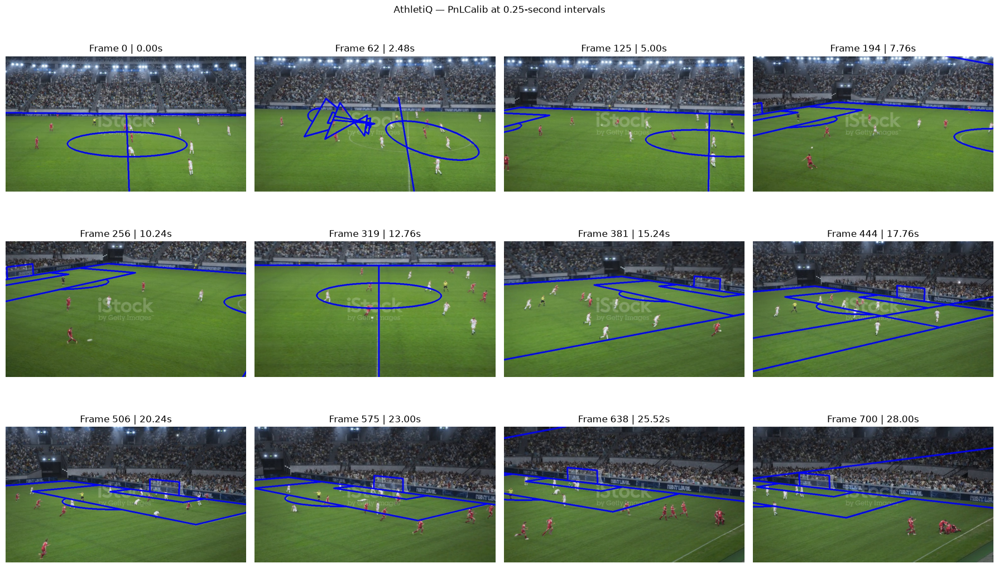

In [35]:

from pathlib import Path
import re
import cv2
import numpy as np
import matplotlib.pyplot as plt

OVERLAY_DIR = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "ai-engine/notebooks/PnLCalib/outputs/calibration/"
    "pnlcalib_025s/overlays"
)

overlays = sorted(
    OVERLAY_DIR.glob("*.jpg"),
    key=lambda p: int(
        re.search(r"frame_(\d+)_", p.name).group(1)
    ),
)

print("Overlay directory:", OVERLAY_DIR)
print("Total overlays:", len(overlays))

if not overlays:
    raise FileNotFoundError(f"No overlays found in {OVERLAY_DIR}")

indices = np.linspace(
    0, len(overlays) - 1, min(12, len(overlays))
).round().astype(int)

selected = [overlays[i] for i in indices]

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
axes = axes.flatten()

for ax, path in zip(axes, selected):
    image = cv2.imread(str(path))
    match = re.search(r"frame_(\d+)_(\d+(?:\.\d+)?)s", path.name)

    if image is None:
        ax.set_title(f"Unreadable: {path.name}")
        ax.axis("off")
        continue

    frame_id = int(match.group(1))
    timestamp = float(match.group(2))

    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(f"Frame {frame_id} | {timestamp:.2f}s")
    ax.axis("off")

for ax in axes[len(selected):]:
    ax.axis("off")

plt.suptitle("AthletiQ — PnLCalib at 0.25-second intervals")
plt.tight_layout()
plt.show()


In [36]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "ai-engine"
    / "notebooks"
    / "PnLCalib"
    / "outputs"
    / "calibration"
    / "pnlcalib_025s"
)

summary_path = OUTPUT_DIR / "calibration_summary.csv"

print("Summary exists:", summary_path.exists())
print("Summary path:", summary_path)

if summary_path.exists():
    df = pd.read_csv(summary_path)

    print("\nShape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nFirst 10 rows:")
    display(df.head(10))

    print("\nRows with highest reprojection error:")
    if "rep_err" in df.columns:
        display(
            df.sort_values("rep_err", ascending=False).head(15)
        )
    else:
        print("No 'rep_err' column found.")


Summary exists: True
Summary path: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/PnLCalib/outputs/calibration/pnlcalib_025s/calibration_summary.csv

Shape: (113, 15)

Columns:
['frame_id', 'time_seconds', 'calibration_returned', 'mode', 'use_ransac', 'rep_err', 'pan_degrees', 'tilt_degrees', 'roll_degrees', 'x_focal_length', 'y_focal_length', 'status', 'overlay_path', 'parameters_path', 'error']

First 10 rows:


,frame_id,time_seconds,calibration_returned,mode,use_ransac,rep_err,pan_degrees,tilt_degrees,roll_degrees,x_focal_length,y_focal_length,status,overlay_path,parameters_path,error
0,0,0.00,True,full,0,1.703178,0.222139,81.018265,-0.473907,1199.043591,1199.043591,candidate_unvalidated,outputs/calibration/pnlcalib_025s/overlays/fra...,outputs/calibration/pnlcalib_025s/parameters/f...,NaN
1,6,0.24,True,full,0,2.279803,0.278407,81.479710,-0.645445,1167.013355,1167.013355,candidate_unvalidated,outputs/calibration/pnlcalib_025s/overlays/fra...,outputs/calibration/pnlcalib_025s/parameters/f...,NaN
2,12,0.48,True,full,0,2.191813,0.302470,81.300054,-0.576369,1154.157164,1154.157164,candidate_unvalidated,outputs/calibration/pnlcalib_025s/overlays/fra...,outputs/calibration/pnlcalib_025s/parameters/f...,NaN
3,19,0.76,True,full,0,1.457103,0.526449,81.444124,-0.516690,1061.152276,1061.152276,candidate_unvalidated,outputs/calibration/pnlcalib_025s/overlays/fra...,outputs/calibration/pnlcalib_025s/parameters/f...,NaN
4,25,1.00,True,full,0,2.024091,0.056149,81.484791,-0.501107,1098.203297,1098.203297,candidate_unvalidated,outputs/calibration/pnlcalib_025s/overlays/fra...,outputs/calibration/pnlcalib_025s/parameters/f...,NaN
5,31,1.24,True,full,0,2.418476,0.023074,81.325023,-0.435236,1149.189651,1149.189651,candidate_unvalidated,outputs/calibration/pnlcalib_025s/overlays/fra...,outputs/calibration/pnlcalib_025s/parameters/f...,NaN
6,38,1.52,True,full,0,2.751500,-0.938390,81.344037,-0.686611,1147.931910,1147.931910,candidate_unvalidated,outputs/calibration/pnlcalib_025s/overlays/fra...,outputs/calibration/pnlcalib_025s/parameters/f...,NaN
7,44,1.76,True,full,0,3.007487,-1.749099,81.173533,-0.464579,1185.502814,1185.502814,candidate_unvalidated,outputs/calibration/pnlcalib_025s/overlays/fra...,outputs/calibration/pnlcalib_025s/parameters/f...,NaN
8,50,2.00,True,full,0,3.121371,-2.897990,81.758341,-0.686254,1091.092836,1091.092836,candidate_unvalidated,outputs/calibration/pnlcalib_025s/overlays/fra...,outputs/calibration/pnlcalib_025s/parameters/f...,NaN
9,56,2.24,True,full,0,3.706540,-3.379346,81.047349,-0.732147,1199.645218,1199.645218,candidate_unvalidated,outputs/calibration/pnlcalib_025s/overlays/fra...,outputs/calibration/pnlcalib_025s/parameters/f...,NaN



Rows with highest reprojection error:


,frame_id,time_seconds,calibration_returned,mode,use_ransac,rep_err,pan_degrees,tilt_degrees,roll_degrees,x_focal_length,y_focal_length,status,overlay_path,parameters_path,error
110,688,27.52,True,full,0,61.493561,103.617966,48.160576,-22.481050,1206.757828,1206.757828,candidate_unvalidated,outputs/calibration/pnlcalib_025s/overlays/fra...,outputs/calibration/pnlcalib_025s/parameters/f...,NaN
108,675,27.00,True,main,0,59.443959,98.214951,59.149863,-19.176165,1168.971964,1168.971964,candidate_unvalidated,outputs/calibration/pnlcalib_025s/overlays/fra...,outputs/calibration/pnlcalib_025s/parameters/f...,NaN
10,62,2.48,True,full,0,56.660520,-80.730471,0.000002,77.073928,0.000002,0.000002,candidate_unvalidated,outputs/calibration/pnlcalib_025s/overlays/fra...,outputs/calibration/pnlcalib_025s/parameters/f...,NaN
106,662,26.48,True,main,0,24.563794,99.100766,48.369261,-20.351323,1154.347672,1154.347672,candidate_unvalidated,outputs/calibration/pnlcalib_025s/overlays/fra...,outputs/calibration/pnlcalib_025s/parameters/f...,NaN
15,94,3.76,True,full,0,4.855182,-11.299288,81.578477,-0.398609,986.559755,986.559755,candidate_unvalidated,outputs/calibration/pnlcalib_025s/overlays/fra...,outputs/calibration/pnlcalib_025s/parameters/f...,NaN
69,431,17.24,True,full,0,4.249236,41.647696,80.188958,0.298052,1111.736293,1111.736293,candidate_unvalidated,outputs/calibration/pnlcalib_025s/overlays/fra...,outputs/calibration/pnlcalib_025s/parameters/f...,NaN
74,462,18.48,True,full,0,4.220069,41.218513,81.235940,0.185506,1138.842209,1138.842209,candidate_unvalidated,outputs/calibration/pnlcalib_025s/overlays/fra...,outputs/calibration/pnlcalib_025s/parameters/f...,NaN
35,219,8.76,True,full,0,3.981459,-29.293436,80.209891,-0.178425,968.645449,968.645449,candidate_unvalidated,outputs/calibration/pnlcalib_025s/overlays/fra...,outputs/calibration/pnlcalib_025s/parameters/f...,NaN
55,344,13.76,True,full,0,3.714303,9.516042,77.358803,0.667311,1179.082960,1179.082960,candidate_unvalidated,outputs/calibration/pnlcalib_025s/overlays/fra...,outputs/calibration/pnlcalib_025s/parameters/f...,NaN
9,56,2.24,True,full,0,3.706540,-3.379346,81.047349,-0.732147,1199.645218,1199.645218,candidate_unvalidated,outputs/calibration/pnlcalib_025s/overlays/fra...,outputs/calibration/pnlcalib_025s/parameters/f...,NaN


Samples: 113
High rep_err (>10): 4
Invalid/nonpositive focal lengths: 0
Extreme-angle flags: 6
Flagged samples (overlapping flags counted once): 6

Saved diagnostics: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/PnLCalib/outputs/calibration/pnlcalib_025s/parameter_stability_diagnostics.csv


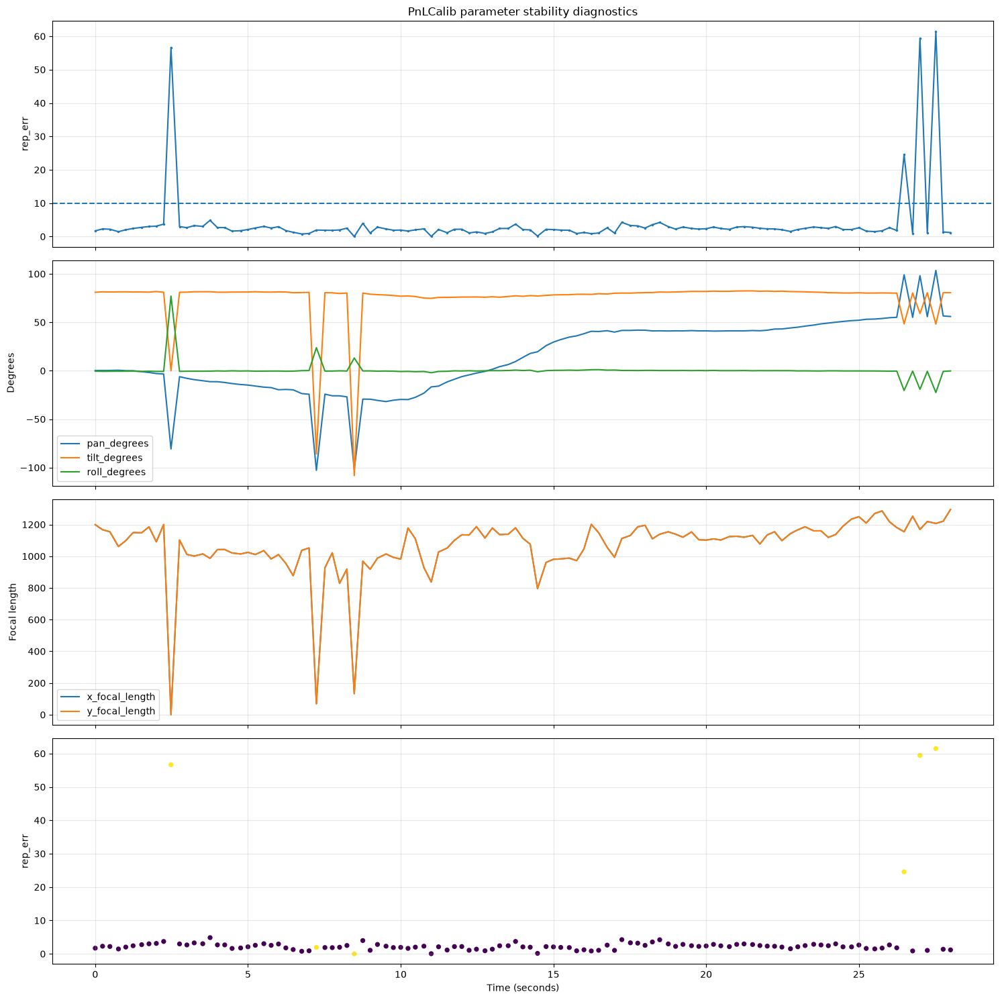


Most suspicious samples:


,frame_id,time_seconds,mode,rep_err,pan_degrees,tilt_degrees,roll_degrees,x_focal_length,y_focal_length
110,688,27.52,full,61.493561,103.617966,48.160576,-22.481050,1206.757828,1206.757828
108,675,27.00,main,59.443959,98.214951,59.149863,-19.176165,1168.971964,1168.971964
10,62,2.48,full,56.660520,-80.730471,0.000002,77.073928,0.000002,0.000002
106,662,26.48,main,24.563794,99.100766,48.369261,-20.351323,1154.347672,1154.347672
29,181,7.24,full,1.944507,-102.820602,-85.971642,23.802557,69.566810,69.566810
34,212,8.48,full,0.000002,-101.949305,-108.296289,13.150066,132.882606,132.882606


In [37]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUTPUT_DIR = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "ai-engine/notebooks/PnLCalib/outputs/"
    "calibration/pnlcalib_025s"
)

CSV_PATH = OUTPUT_DIR / "calibration_summary.csv"
DIAGNOSTICS_PATH = OUTPUT_DIR / "parameter_stability_diagnostics.csv"

df = pd.read_csv(CSV_PATH).sort_values("time_seconds").reset_index(drop=True)

numeric_cols = [
    "time_seconds", "rep_err", "pan_degrees",
    "tilt_degrees", "roll_degrees",
    "x_focal_length", "y_focal_length"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Parameter changes between consecutive samples.
for col in [
    "pan_degrees", "tilt_degrees", "roll_degrees",
    "x_focal_length", "y_focal_length"
]:
    df[f"{col}_step"] = df[col].diff().abs()

# Conservative diagnostic flags; these are not model-specific
# acceptance thresholds or proof of calibration failure.
df["flag_high_rep_err"] = df["rep_err"] > 10
df["flag_invalid_focal"] = (
    (df["x_focal_length"] <= 0)
    | (df["y_focal_length"] <= 0)
    | ~np.isfinite(df["x_focal_length"])
    | ~np.isfinite(df["y_focal_length"])
)
df["flag_extreme_angles"] = (
    (df["tilt_degrees"].abs() < 1)
    | (df["roll_degrees"].abs() > 10)
    | (df["pan_degrees"].abs() > 90)
)

df["flag_suspicious"] = (
    df["flag_high_rep_err"]
    | df["flag_invalid_focal"]
    | df["flag_extreme_angles"]
)

df.to_csv(DIAGNOSTICS_PATH, index=False)

print("Samples:", len(df))
print("High rep_err (>10):", int(df["flag_high_rep_err"].sum()))
print("Invalid/nonpositive focal lengths:", int(df["flag_invalid_focal"].sum()))
print("Extreme-angle flags:", int(df["flag_extreme_angles"].sum()))
print("Flagged samples (overlapping flags counted once):",
      int(df["flag_suspicious"].sum()))
print("\nSaved diagnostics:", DIAGNOSTICS_PATH)

fig, axes = plt.subplots(4, 1, figsize=(15, 15), sharex=True)

axes[0].plot(df["time_seconds"], df["rep_err"], marker=".", markersize=3)
axes[0].axhline(10, linestyle="--")
axes[0].set_ylabel("rep_err")
axes[0].set_title("PnLCalib parameter stability diagnostics")
axes[0].grid(True, alpha=0.3)

for col in ["pan_degrees", "tilt_degrees", "roll_degrees"]:
    axes[1].plot(df["time_seconds"], df[col], label=col)
axes[1].set_ylabel("Degrees")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].plot(df["time_seconds"], df["x_focal_length"], label="x_focal_length")
axes[2].plot(df["time_seconds"], df["y_focal_length"], label="y_focal_length")
axes[2].set_ylabel("Focal length")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

axes[3].scatter(
    df["time_seconds"],
    df["rep_err"],
    c=df["flag_suspicious"].astype(int),
    s=18
)
axes[3].set_xlabel("Time (seconds)")
axes[3].set_ylabel("rep_err")
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nMost suspicious samples:")
display(
    df.loc[df["flag_suspicious"],
           ["frame_id", "time_seconds", "mode", "rep_err",
            "pan_degrees", "tilt_degrees", "roll_degrees",
            "x_focal_length", "y_focal_length"]]
      .sort_values("rep_err", ascending=False)
      .head(20)
)


Video FPS: 25.0, frames: 705


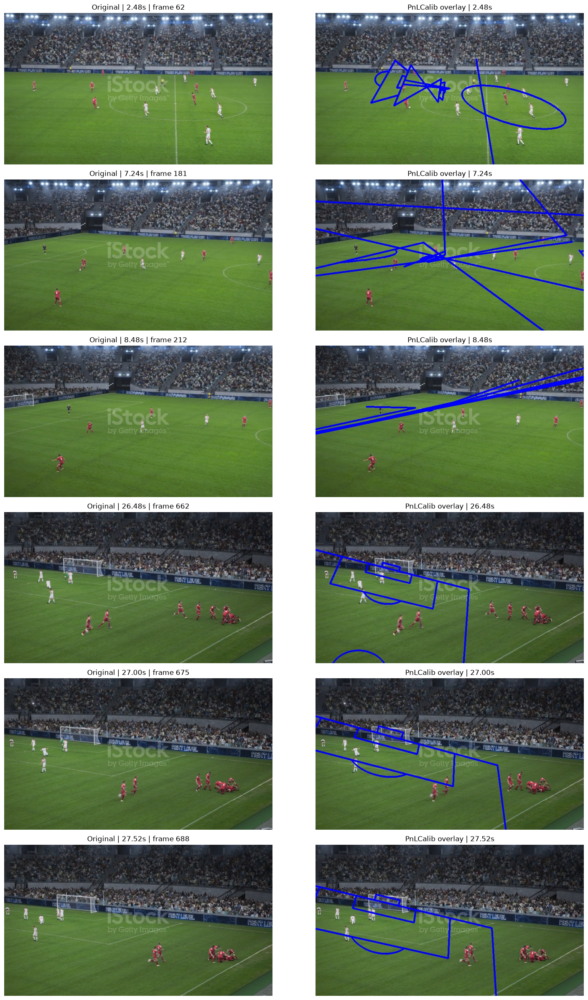

In [38]:

from pathlib import Path
import re
import cv2
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

VIDEO_PATH = PROJECT_DIR / "datasets/football/raw/videos/football2.mp4"

OUTPUT_DIR = (
    PROJECT_DIR
    / "ai-engine/notebooks/PnLCalib/outputs/calibration/pnlcalib_025s"
)

OVERLAY_DIR = OUTPUT_DIR / "overlays"

TARGET_TIMES = [2.48, 7.24, 8.48, 26.48, 27.00, 27.52]

cap = cv2.VideoCapture(str(VIDEO_PATH))
if not cap.isOpened():
    raise FileNotFoundError(f"Could not open video: {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print(f"Video FPS: {fps}, frames: {frame_count}")

# Index overlays by their timestamp.
overlay_by_time = {}
for path in OVERLAY_DIR.glob("*.jpg"):
    match = re.search(r"_(\d+(?:\.\d+)?)s\.jpg$", path.name)
    if match:
        overlay_by_time[round(float(match.group(1)), 2)] = path

fig, axes = plt.subplots(
    len(TARGET_TIMES), 2, figsize=(16, 4 * len(TARGET_TIMES))
)

for row, t in enumerate(TARGET_TIMES):
    frame_id = round(t * fps)

    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_id)
    ok, frame = cap.read()

    if ok:
        axes[row, 0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        axes[row, 0].set_title(f"Original | {t:.2f}s | frame {frame_id}")
    else:
        axes[row, 0].set_title(f"Could not read original at {t:.2f}s")

    overlay_path = overlay_by_time.get(round(t, 2))
    if overlay_path and overlay_path.exists():
        overlay = cv2.imread(str(overlay_path))
        if overlay is not None:
            axes[row, 1].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
            axes[row, 1].set_title(f"PnLCalib overlay | {t:.2f}s")
        else:
            axes[row, 1].set_title(f"Could not read overlay at {t:.2f}s")
    else:
        axes[row, 1].set_title(f"Overlay not found at {t:.2f}s")

    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

cap.release()
plt.tight_layout()
plt.show()


In [39]:

from pathlib import Path

REPO = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "ai-engine/notebooks/PnLCalib"
)

keywords = [
    "cam_params",
    "pan_degrees",
    "tilt_degrees",
    "roll_degrees",
    "rep_err",
    "projectPoints",
    "homography",
    "get_projection",
]

extensions = {".py"}

for path in REPO.rglob("*"):
    if not path.is_file() or path.suffix not in extensions:
        continue

    # Skip generated outputs and virtual environments.
    if any(part in {
        ".git", "__pycache__", "outputs", ".venv", "venv"
    } for part in path.parts):
        continue

    try:
        lines = path.read_text(
            encoding="utf-8", errors="ignore"
        ).splitlines()
    except OSError:
        continue

    hits = [
        i for i, line in enumerate(lines)
        if any(word.lower() in line.lower() for word in keywords)
    ]

    if not hits:
        continue

    print(f"\n{'=' * 90}\nFILE: {path}")

    shown = set()
    for i in hits:
        start = max(0, i - 3)
        end = min(len(lines), i + 5)

        # Avoid printing overlapping context repeatedly.
        if any(j in shown for j in range(start, end)):
            continue

        for j in range(start, end):
            print(f"{j + 1:4}: {lines[j]}")
            shown.add(j)
        print("-" * 50)



FILE: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/PnLCalib/eval_wp.py
 167:                     args.pnl_refine
 168:                 )
 169: 
 170:                 cam_params = final_params_dict["cam_params"]
 171:                 R = np.array(cam_params["rotation_matrix"])
 172:                 t = np.array(cam_params["position_meters"])
 173:                 t = -R @ t
 174: 
--------------------------------------------------

FILE: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/PnLCalib/inference.py
  44:                 [[99.5, 24.84, 0.], [105., 24.84, 0.]]]
  45: 
  46: 
  47: def projection_from_cam_params(final_params_dict):
  48:     cam_params = final_params_dict["cam_params"]
  49:     x_focal_length = cam_params['x_focal_length']
  50:     y_focal_length = cam_params['y_focal_length']
  51:     principal_point = np.array(cam_params['principal_point'])
--------------------------------------------------
 160: 
 161:             final_params_dict = inf

In [40]:

from pathlib import Path
import ast

REPO = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "ai-engine/notebooks/PnLCalib"
)

TARGETS = {
    "inference.py": [
        "projection_from_cam_params",
        "project",
    ],
    "utils/utils_calib.py": [
        "heuristic_voting",
        "get_cam_params",
    ],
}

def print_function(path, function_name):
    source = path.read_text(encoding="utf-8", errors="ignore")
    tree = ast.parse(source)

    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            if node.name == function_name:
                lines = source.splitlines()
                print(f"\n{'=' * 90}")
                print(f"FILE: {path}")
                print(f"FUNCTION: {function_name}")
                print(f"LINES: {node.lineno}-{node.end_lineno}")
                print("=" * 90)

                for line_number in range(node.lineno, node.end_lineno + 1):
                    print(f"{line_number:4}: {lines[line_number - 1]}")
                return

    print(f"\nFunction {function_name!r} not found in {path}")

for relative_path, function_names in TARGETS.items():
    path = REPO / relative_path

    if not path.exists():
        print(f"FILE NOT FOUND: {path}")
        continue

    for function_name in function_names:
        print_function(path, function_name)



FILE: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/PnLCalib/inference.py
FUNCTION: projection_from_cam_params
LINES: 47-62
  47: def projection_from_cam_params(final_params_dict):
  48:     cam_params = final_params_dict["cam_params"]
  49:     x_focal_length = cam_params['x_focal_length']
  50:     y_focal_length = cam_params['y_focal_length']
  51:     principal_point = np.array(cam_params['principal_point'])
  52:     position_meters = np.array(cam_params['position_meters'])
  53:     rotation = np.array(cam_params['rotation_matrix'])
  54: 
  55:     It = np.eye(4)[:-1]
  56:     It[:, -1] = -position_meters
  57:     Q = np.array([[x_focal_length, 0, principal_point[0]],
  58:                   [0, y_focal_length, principal_point[1]],
  59:                   [0, 0, 1]])
  60:     P = Q @ (rotation @ It)
  61: 
  62:     return P

FILE: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/PnLCalib/inference.py
FUNCTION: project
LINES: 91-135
  91: def project(frame

In [41]:

from pathlib import Path
import ast

REPO = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "ai-engine/notebooks/PnLCalib"
)

TARGETS = {
    "utils/utils_calib.py": [
        "change_plane_coords",
        "get_per_plane_correspondences",
        "get_correspondences",
        "reproj_err",
    ],
    "inference.py": [
        "inference",
    ],
}

def show_function(relative_path, function_name):
    path = REPO / relative_path
    source = path.read_text(encoding="utf-8", errors="ignore")
    lines = source.splitlines()
    tree = ast.parse(source)

    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            if node.name == function_name:
                print(f"\n{'=' * 80}")
                print(f"{relative_path} :: {function_name}")
                print(f"Lines {node.lineno}-{node.end_lineno}")
                print("=" * 80)

                for i in range(node.lineno - 1, node.end_lineno):
                    print(f"{i + 1:4}: {lines[i]}")
                return

    print(f"Function not found: {relative_path} :: {function_name}")

for relative_path, function_names in TARGETS.items():
    for function_name in function_names:
        show_function(relative_path, function_name)

# Also print the canonical pitch line definitions used by inference.py.
path = REPO / "inference.py"
lines = path.read_text(encoding="utf-8", errors="ignore").splitlines()

print("\n" + "=" * 80)
print("inference.py :: top-level pitch definitions")
print("=" * 80)

for i, line in enumerate(lines[:48], start=1):
    print(f"{i:4}: {line}")



utils/utils_calib.py :: change_plane_coords
Lines 227-233
 227:     def change_plane_coords(self, w=105, h=68):
 228:         R = np.array([[0,0,-1], [0,1,0], [1,0,0]])
 229:         self.rotation = self.rotation @ R
 230:         if self.ord_pts[0] == 1:
 231:             self.position = np.linalg.inv(R) @ self.position + np.array([-w/2, 0, 0])
 232:         elif self.ord_pts[0] == 2:
 233:             self.position = np.linalg.inv(R) @ self.position + np.array([w/2, 0, 0])

utils/utils_calib.py :: get_per_plane_correspondences
Lines 144-216
 144:     def get_per_plane_correspondences(self, mode, use_ransac):
 145:         self.obj_pts, self.img_pts, self.ord_pts = None, None, None
 146: 
 147:         if mode not in ['full', 'main', 'ground_plane']:
 148:             sys.exit("Wrong mode. Select mode between 'full', 'main_keypoints', 'ground_plane'")
 149: 
 150:         world_points_p1, world_points_p2, world_points_p3 = [], [], []
 151:         img_points_p1, img_points_p2, img_po

In [42]:

from pathlib import Path
import json
import numpy as np

REPO = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "ai-engine/notebooks/PnLCalib"
)

PARAM_DIR = (
    REPO / "outputs" / "calibration"
    / "pnlcalib_025s" / "parameters"
)

files = sorted(PARAM_DIR.glob("*.json"))

print("Parameter directory:", PARAM_DIR)
print("JSON parameter files:", len(files))

if not files:
    print("No JSON files found. Available files:")
    if PARAM_DIR.exists():
        for p in list(PARAM_DIR.iterdir())[:15]:
            print(" ", p.name)
    else:
        print("Directory does not exist.")
else:
    # Inspect the saved schema before assuming its structure.
    sample = files[0]
    data = json.loads(sample.read_text(encoding="utf-8"))

    print("\nSample file:", sample.name)
    print("Top-level type:", type(data).__name__)

    if isinstance(data, dict):
        print("Top-level keys:", list(data.keys()))

        if "cam_params" in data:
            cam = data["cam_params"]
            print("\nCamera parameter keys:", list(cam.keys()))

            required = [
                "x_focal_length",
                "y_focal_length",
                "principal_point",
                "position_meters",
                "rotation_matrix",
            ]

            missing = [k for k in required if k not in cam]
            print("Missing camera fields:", missing)

            if not missing:
                fx = float(cam["x_focal_length"])
                fy = float(cam["y_focal_length"])
                cx, cy = map(float, cam["principal_point"])
                position = np.asarray(
                    cam["position_meters"], dtype=float
                )
                rotation = np.asarray(
                    cam["rotation_matrix"], dtype=float
                )

                K = np.array([
                    [fx, 0, cx],
                    [0, fy, cy],
                    [0, 0, 1],
                ], dtype=float)

                extrinsic = np.eye(4)[:3]
                extrinsic[:, 3] = -position

                P = K @ rotation @ extrinsic

                # Test basic mathematical validity.
                print("\nProjection matrix shape:", P.shape)
                print("All projection values finite:", np.isfinite(P).all())
                print("Focal lengths:", fx, fy)
                print("Rotation orthogonality error:",
                      np.linalg.norm(rotation @ rotation.T - np.eye(3)))
                print("Rotation determinant:", np.linalg.det(rotation))
                print("Camera position:", position)
                print("\nProjection matrix:\n", P)
        else:
            print(
                "\nThis JSON does not contain 'cam_params'. "
                "Inspect the keys above before proceeding."
            )
    else:
        print("Inspect the sample structure before proceeding:")
        print(str(data)[:1500])


Parameter directory: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/PnLCalib/outputs/calibration/pnlcalib_025s/parameters
JSON parameter files: 113

Sample file: frame_000000_0000.00s.json
Top-level type: dict
Top-level keys: ['mode', 'use_ransac', 'rep_err', 'cam_params', 'calib_plane']

Camera parameter keys: ['pan_degrees', 'tilt_degrees', 'roll_degrees', 'x_focal_length', 'y_focal_length', 'principal_point', 'position_meters', 'rotation_matrix', 'radial_distortion', 'tangential_distortion', 'thin_prism_distortion']
Missing camera fields: []

Projection matrix shape: (3, 4)
All projection values finite: True
Focal lengths: 1199.043590854269 1199.043590854269
Rotation orthogonality error: 3.474864290052905e-17
Rotation determinant: 1.0
Camera position: [ -0.47748474  57.12540306 -11.95339394]

Projection matrix:
 [[ 1.20046818e+03 -3.75694445e+02  5.00760230e+01  2.26334803e+04]
 [ 1.00168999e+01 -2.56311216e+01  1.21794437e+03  1.60275399e+04]
 [ 3.82950696e-03 -9.87730735

Original video: 768 x 432
Inference size: 960 x 540
Scale factors: 0.8 0.8


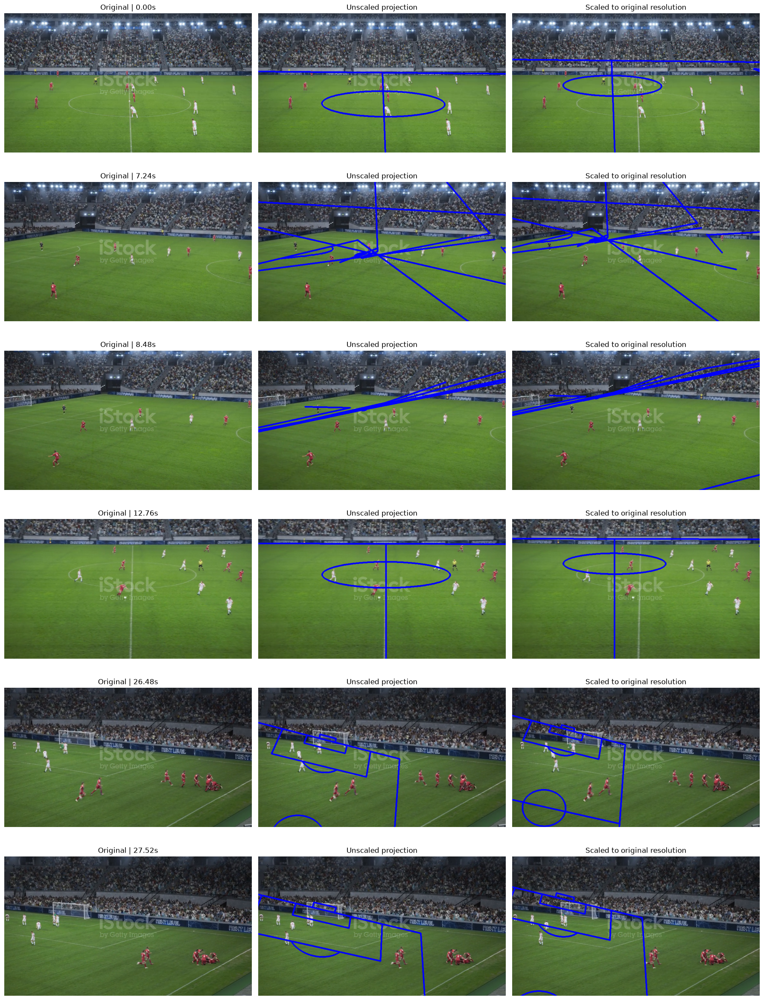


Scaled comparison images saved to: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/PnLCalib/outputs/calibration/scale_test


In [43]:

from pathlib import Path
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
import sys

REPO = Path(
    "/mnt/d/My Projects/AthletiQ/AthletiQ/"
    "ai-engine/notebooks/PnLCalib"
)
PROJECT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")

VIDEO = PROJECT / "datasets/football/raw/videos/football2.mp4"
PARAM_DIR = REPO / "outputs/calibration/pnlcalib_025s/parameters"
OUT_DIR = REPO / "outputs/calibration/scale_test"
OUT_DIR.mkdir(parents=True, exist_ok=True)

if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from inference import project

cap = cv2.VideoCapture(str(VIDEO))
assert cap.isOpened(), f"Cannot open video: {VIDEO}"

original_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
original_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

sx = original_w / 960.0
sy = original_h / 540.0

print("Original video:", original_w, "x", original_h)
print("Inference size: 960 x 540")
print("Scale factors:", sx, sy)

# Representative timestamps, including previously problematic frames.
times = [0.0, 7.24, 8.48, 12.76, 26.48, 27.52]
fig, axes = plt.subplots(len(times), 3, figsize=(18, 4 * len(times)))

for row, t in enumerate(times):
    frame_id = round(t * fps)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_id)
    ok, frame = cap.read()

    if not ok:
        print("Could not read frame at", t)
        continue

    param_file = min(
        PARAM_DIR.glob("*.json"),
        key=lambda p: abs(
            float(p.stem.split("_")[-1].replace("s", "")) - t
        ),
        default=None,
    )

    if param_file is None:
        raise FileNotFoundError(f"No parameter JSONs in {PARAM_DIR}")

    params = json.loads(param_file.read_text(encoding="utf-8"))
    cam = params["cam_params"]

    K = np.array([
        [cam["x_focal_length"], 0, cam["principal_point"][0]],
        [0, cam["y_focal_length"], cam["principal_point"][1]],
        [0, 0, 1],
    ], dtype=float)

    R = np.asarray(cam["rotation_matrix"], dtype=float)
    C = np.asarray(cam["position_meters"], dtype=float)

    extrinsic = np.eye(4)[:3]
    extrinsic[:, 3] = -C
    P = K @ R @ extrinsic

    # Convert projected image coordinates to original-frame pixels.
    S = np.diag([sx, sy, 1.0])
    P_scaled = S @ P

    overlay_unscaled = project(frame.copy(), P)
    overlay_scaled = project(frame.copy(), P_scaled)

    axes[row, 0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    axes[row, 0].set_title(f"Original | {t:.2f}s")

    axes[row, 1].imshow(cv2.cvtColor(overlay_unscaled, cv2.COLOR_BGR2RGB))
    axes[row, 1].set_title("Unscaled projection")

    axes[row, 2].imshow(cv2.cvtColor(overlay_scaled, cv2.COLOR_BGR2RGB))
    axes[row, 2].set_title("Scaled to original resolution")

    for ax in axes[row]:
        ax.axis("off")

    out_path = OUT_DIR / f"scaled_comparison_{frame_id:06d}.jpg"
    cv2.imwrite(str(out_path), overlay_scaled)

cap.release()
plt.tight_layout()
plt.show()

print("\nScaled comparison images saved to:", OUT_DIR)


In [44]:

from pathlib import Path
import sys
import cv2
import json
import numpy as np
import matplotlib.pyplot as plt

PROJECT = Path("/mnt/d/My Projects/AthletiQ/AthletiQ")
REPO = PROJECT / "ai-engine/notebooks/PnLCalib"

VIDEO = PROJECT / "datasets/football/raw/videos/football2.mp4"
PARAM_DIR = REPO / "outputs/calibration/pnlcalib_025s/parameters"
OUT_DIR = REPO / "outputs/calibration/keypoint_diagnostics"

OUT_DIR.mkdir(parents=True, exist_ok=True)

if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

print("Video exists:", VIDEO.exists())
print("PnLCalib repo exists:", REPO.exists())
print("Parameter directory exists:", PARAM_DIR.exists())
print("Parameter JSON count:", len(list(PARAM_DIR.glob("*.json"))))
print("Diagnostic output:", OUT_DIR)


Video exists: True
PnLCalib repo exists: True
Parameter directory exists: True
Parameter JSON count: 113
Diagnostic output: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/PnLCalib/outputs/calibration/keypoint_diagnostics


In [45]:

import ast

source_files = [
    REPO / "inference.py",
    REPO / "utils" / "utils_calib.py",
]

for file_path in source_files:
    print(f"\n{'=' * 70}\nFILE: {file_path}\n{'=' * 70}")

    if not file_path.exists():
        print("File not found")
        continue

    source = file_path.read_text(encoding="utf-8")
    tree = ast.parse(source)

    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            print(f"{node.lineno:4}: {node.name}")

    for lineno, line in enumerate(source.splitlines(), start=1):
        if any(term in line.lower() for term in [
            "complete_keypoints",
            "keypoint",
            "lines_dict",
            "kp_dict",
            "def inference",
        ]):
            print(f"{lineno:4}: {line.strip()}")



FILE: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/PnLCalib/inference.py
  47: projection_from_cam_params
  65: inference
  91: project
 138: process_input
  18: from utils.utils_heatmap import get_keypoints_from_heatmap_batch_maxpool, get_keypoints_from_heatmap_batch_maxpool_l, \
  19: complete_keypoints, coords_to_dict
  65: def inference(cam, frame, model, model_l, kp_threshold, line_threshold, pnl_refine):
  79: kp_coords = get_keypoints_from_heatmap_batch_maxpool(heatmaps[:,:-1,:,:])
  80: line_coords = get_keypoints_from_heatmap_batch_maxpool_l(heatmaps_l[:,:-1,:,:])
  81: kp_dict = coords_to_dict(kp_coords, threshold=kp_threshold)
  82: lines_dict = coords_to_dict(line_coords, threshold=line_threshold)
  83: kp_dict, lines_dict = complete_keypoints(kp_dict[0], lines_dict[0], w=w, h=h, normalize=True)
  85: cam.update(kp_dict, lines_dict)
 206: parser.add_argument("--weights_kp", type=str, help="Path to the model for keypoint inference.")
 208: parser.add_argument("-

In [46]:

# Inspect the exact inference pipeline and model-loading code.
# This is read-only; it does not run inference.

source_path = REPO / "inference.py"
source_lines = source_path.read_text(encoding="utf-8").splitlines()

for start, end in [(1, 105), (130, 205)]:
    print(f"\n{'=' * 25} inference.py lines {start}-{end} {'=' * 25}")
    for i in range(start, min(end, len(source_lines)) + 1):
        print(f"{i:4}: {source_lines[i - 1]}")

heatmap_path = REPO / "utils" / "utils_heatmap.py"
if heatmap_path.exists():
    heatmap_lines = heatmap_path.read_text(encoding="utf-8").splitlines()
    print(f"\n{'=' * 20} utils_heatmap.py {'=' * 20}")
    for i, line in enumerate(heatmap_lines, start=1):
        if any(term in line for term in [
            "def get_keypoints_from_heatmap_batch_maxpool",
            "def get_keypoints_from_heatmap_batch_maxpool_l",
            "def coords_to_dict",
            "def complete_keypoints",
        ]):
            lo, hi = max(1, i - 2), min(len(heatmap_lines), i + 28)
            print(f"\n--- lines {lo}-{hi} ---")
            for j in range(lo, hi + 1):
                print(f"{j:4}: {heatmap_lines[j - 1]}")



========================= inference.py lines 1-105 =========================
   1: import cv2
   2: import yaml
   3: import torch
   4: import argparse
   5: import numpy as np
   6: import matplotlib.pyplot as plt
   7: import torchvision.transforms as T
   8: import torchvision.transforms.functional as f
   9: 
  10: from tqdm import tqdm
  11: from PIL import Image
  12: from matplotlib.patches import Polygon
  13: 
  14: from model.cls_hrnet import get_cls_net
  15: from model.cls_hrnet_l import get_cls_net as get_cls_net_l
  16: 
  17: from utils.utils_calib import FramebyFrameCalib, pan_tilt_roll_to_orientation
  18: from utils.utils_heatmap import get_keypoints_from_heatmap_batch_maxpool, get_keypoints_from_heatmap_batch_maxpool_l, \
  19:     complete_keypoints, coords_to_dict
  20: 
  21: 
  22: lines_coords = [[[0., 54.16, 0.], [16.5, 54.16, 0.]],
  23:                 [[16.5, 13.84, 0.], [16.5, 54.16, 0.]],
  24:                 [[16.5, 13.84, 0.], [0., 13.84, 0.]],
  25: 

In [47]:

import inference

print("Inference module:", inference.__file__)
print("Device:", getattr(inference, "device", "Not defined"))
print("Transform:", getattr(inference, "transform2", "Not defined"))

# Look for models already loaded in the notebook.
for name in ["model", "model_l", "model_kp", "model_line"]:
    obj = globals().get(name)
    print(f"{name}:",
          type(obj).__name__ if obj is not None else "not found")

# Check the inference function's required arguments.
import inspect
print("\ninference() signature:")
print(inspect.signature(inference.inference))


Inference module: /mnt/d/My Projects/AthletiQ/AthletiQ/ai-engine/notebooks/PnLCalib/inference.py
Device: cuda:0
Transform: Resize(size=(540, 960), interpolation=bilinear, max_size=None, antialias=True)
model: not found
model_l: not found
model_kp: HighResolutionNet
model_line: not found

inference() signature:
(cam, frame, model, model_l, kp_threshold, line_threshold, pnl_refine)
